In [2]:
pip install --upgrade numexpr bottleneck

Note: you may need to restart the kernel to use updated packages.Requirement already satisfied: numexpr in c:\users\meenakshi m\anaconda3\lib\site-packages (2.8.7)
  Attempting uninstall: numexpr
    Found existing installation: numexpr 2.8.7
    Uninstalling numexpr-2.8.7:
      Successfully uninstalled numexpr-2.8.7
  Attempting uninstall: bottleneck
    Found existing installation: Bottleneck 1.3.7
    Uninstalling Bottleneck-1.3.7:
      Successfully uninstalled Bottleneck-1.3.7



  You can safely remove it manually.
  You can safely remove it manually.


In [79]:
import pandas as pd
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.model_selection import GridSearchCV
import matplotlib.pyplot as plt
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    confusion_matrix,
)

In [80]:
# UCI Statlog German Credit Data (raw text format, space-separated with no header)
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data"

In [81]:
# Define standard column names for the 20 features + target (last column 'class': 1 = Good, 2 = Bad)
columns = [
    "checking_account",
    "duration",
    "credit_history",
    "purpose",
    "credit_amount",
    "savings",
    "employment_since",
    "installment_rate",
    "personal_status_sex",
    "other_debtors",
    "residence_since",
    "property",
    "age",
    "other_installment_plans",
    "housing",
    "existing_credits",
    "job",
    "people_liable",
    "telephone",
    "foreign_worker",
    "credit_risk",
]

In [82]:
df = pd.read_csv(url,sep=" ", header=None, names=columns)

In [83]:
# Map target to binary (1: Good risk -> 1, 2: Bad risk -> 0)

In [84]:
df["credit_risk"] = df["credit_risk"].map({1: 1, 2: 0})

In [85]:
print(df.head())
print(df["credit_risk"].value_counts(normalize=True))

  checking_account  duration credit_history purpose  credit_amount savings  \
0              A11         6            A34     A43           1169     A65   
1              A12        48            A32     A43           5951     A61   
2              A14        12            A34     A46           2096     A61   
3              A11        42            A32     A42           7882     A61   
4              A11        24            A33     A40           4870     A61   

  employment_since  installment_rate personal_status_sex other_debtors  ...  \
0              A75                 4                 A93          A101  ...   
1              A73                 2                 A92          A101  ...   
2              A74                 2                 A93          A101  ...   
3              A74                 2                 A93          A103  ...   
4              A73                 3                 A93          A101  ...   

   property age  other_installment_plans housing existin

In [86]:
# 1. Separate features and target

X = df.drop(columns=["credit_risk"])
y = df["credit_risk"]

In [87]:
# Identify numeric and categorical columns dynamically
numerical_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols = X.select_dtypes(include=["object","str", "category", "int64"]).columns.tolist()
# Note: In german.data, some categorical variables are integers (like 1, 2, 3).
# Let's explicitly define categorical features based on domain knowledge if needed,
# but for now, let's treat object columns as categorical and specific low-cardinality intege

In [88]:
# Better explicit separation for German Credit dataset:
categorical_cols = [
    "checking_account",
    "credit_history",
    "purpose",
    "savings",
    "employment_since",
    "personal_status_sex",
    "other_debtors",
    "property",
    "other_installment_plans",
    "housing",
    "job",
    "telephone",
    "foreign_worker",
]
numeric_cols = [
    "duration",
    "credit_amount",
    "installment_rate",
    "residence_since",
    "age",
    "existing_credits",
    "people_liable",
]

In [89]:
# 2. Stratified train-test split (crucial for credit risk / imbalanced data)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [90]:
# 3. Build sub-pipelines for preprocessing
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore", sparse_output=False, drop="first"
            ),
        ),
    ]
)

In [91]:
# Combine into a single preprocessor using ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_cols),
        ("cat", categorical_transformer, categorical_cols),
    ]
)

In [92]:
# 1. Combine preprocessor and model into a single Pipeline
full_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(random_state=42)),
    ]
)

In [93]:
# 2. Define hyperparameters to tune
# Note the 'classifier__' prefix required in pipelines

param_grid = {
    "classifier__n_estimators": [50, 100, 200],
    "classifier__max_depth": [5, 10, None],
    "classifier__min_samples_split": [2, 5, 10],
}

In [94]:
#Set up GridSearchCV with 5-fold cross-validation and ROC-AUC scoring
grid_search = GridSearchCV(
    estimator=full_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1,
)

In [95]:
#4. Train the model on the training set
grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__max_depth': [5, 10, ...], 'classifier__min_samples_split': [2, 5, ...], 'classifier__n_estimators': [50, 100, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold an

In [96]:
#5. Evaluate on the test set
print(f"Best Hyperparameters: {grid_search.best_params_}")
print(f"Best Cross-Validation ROC-AUC:{grid_search.best_score_:.4f}\n")

Best Hyperparameters: {'classifier__max_depth': None, 'classifier__min_samples_split': 10, 'classifier__n_estimators': 200}
Best Cross-Validation ROC-AUC:0.7809



In [97]:
y_pred = grid_search.predict(X_test)
y_prob = grid_search.predict_proba(X_test)[:, 1]

print(f"Test Set ROC-AUC: {roc_auc_score(y_test, y_prob):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))
      

Test Set ROC-AUC: 0.7758

Classification Report:
              precision    recall  f1-score   support

           0       0.63      0.40      0.49        60
           1       0.78      0.90      0.83       140

    accuracy                           0.75       200
   macro avg       0.70      0.65      0.66       200
weighted avg       0.73      0.75      0.73       200



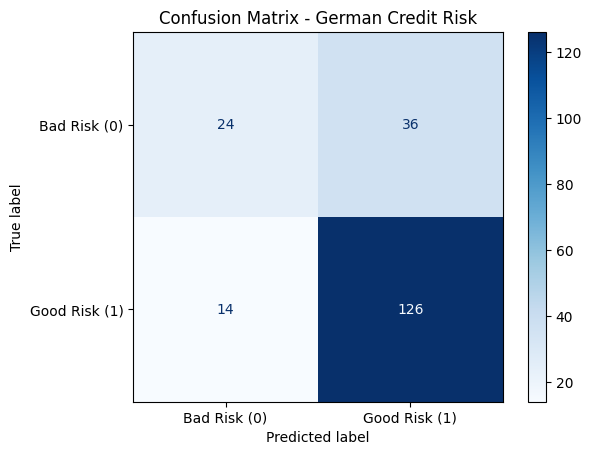

In [98]:
#6. Plot the confusion matrix
#Rows = True labels, columns = Predicted labels 

cm = confusion_matrix(y_test, y_pred)
disp_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=["Bad Risk (0)", "Good Risk (1)"]
)

disp_cm.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix - German Credit Risk")
plt.show()

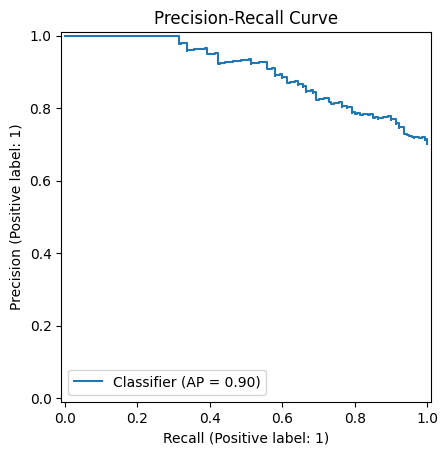

In [99]:
# 2. Plot the Precision-Recall Curve
y_prob = grid_search.predict_proba(X_test)[:, 1]
disp_pr = PrecisionRecallDisplay.from_predictions(y_test, y_prob)

plt.title("Precision-Recall Curve")
plt.show()

In [100]:
# Get predicted probabilities for the positive class (Good Risk: 1)
y_prob = grid_search.predict_proba(X_test)[:, 1]

In [102]:
# Define business costs
# Cost of False Negative (giving loan to a default risk): High penalty (e.g., ₹50,000)
# Cost of False Positive (rejecting a good customer): Lower opportunity cost (e.g., ₹5,000)
cost_fn = 50000
cost_fp = 5000

thresholds = np.linspace(0.1, 0.9, 81)
best_threshold = 0.5
min_total_cost = float("inf")

In [103]:
cost_history = []

for thresh in thresholds:
  # Convert probabilities to binary predictions based on current threshold
  y_pred_thresh = (y_prob >= thresh).astype(int)

  # Get confusion matrix elements: [[TN, FP], [FN, TP]]
  tn, fp, fn, tp = confusion_matrix(y_test, y_pred_thresh).ravel()

  # Calculate total business cost for this threshold
  total_cost = (fn * cost_fn) + (fp * cost_fp)
  cost_history.append((thresh, total_cost))

  if total_cost < min_total_cost:
    min_total_cost = total_cost
    best_threshold = thresh

print(f"Optimal Threshold to Minimize Business Cost: {best_threshold:.2f}")
print(f"Minimum Total Cost at this threshold: ₹{min_total_cost:,.2f}")

Optimal Threshold to Minimize Business Cost: 0.35
Minimum Total Cost at this threshold: ₹285,000.00
